<h1 align="center"><strong>SPAM EMAIL CLASSIFICATION</strong></h1>
<h2>Javairiya Naeem</h2>
<p><b>Dataset:</b> Spam Mails Dataset (Kaggle)</p>
<p><b>Problem Type:</b> Binary Classification</p>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving spam_ham_dataset.csv to spam_ham_dataset.csv


# **PART 1 — Understanding and Data Collection**

**1. Understanding Spam vs Legitimate Emails**

---



***Spam Emails***

Unwanted or unsolicited emails that may contain advertisements, misleading offers, suspicious links or fraudulent messages.

Example: "Congratulations! You have won a free iPhone. Click here to claim your prize."


***Legitimate (Ham) Emails***

Genuine emails sent for normal communication, work, education, business or personal purposes.

Example: "Hello, please find the meeting agenda attached. Our meeting is scheduled for tomorrow."

**2. Dataset Collection**

---



This project uses the Spam Mails Dataset obtained from Kaggle. It contains email messages labeled as Spam or Ham. The dataset will be used to develop a machine learning-based email classification system.

Dataset: https://www.kaggle.com/datasets/venky73/spam-mails-dataset

**3. Import Libraries and Load Dataset**

---



In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("spam_ham_dataset.csv")

# Display first five records
df.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


**4. Explore Dataset Structure**

---



*a. Dataset dimensions*

In [ ]:
df.shape

(5171, 4)

*b. Column names*

In [ ]:
df.columns

Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')

*c. Dataset information*

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  5171 non-null   int64 
 1   label       5171 non-null   object
 2   text        5171 non-null   object
 3   label_num   5171 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 161.7+ KB


*d. Missing values*

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
label,0
text,0
label_num,0


*e. Duplicate records*


In [ ]:
df.duplicated().sum()

np.int64(0)

*f. Label distribution*

In [ ]:
df["label"].value_counts()

,count
label,
ham,3672
spam,1499


**5. Identify Spam and Non-Spam Examples**

---



In [ ]:
# Spam email examples
df[df["label"] == "spam"]["text"].head(3)

,text
3,"Subject: photoshop , windows , office . cheap ..."
7,Subject: looking for medication ? we ` re the ...
10,Subject: vocable % rnd - word asceticism\r\nvc...


In [ ]:
# Legitimate email examples
df[df["label"] == "ham"]["text"].head(3)

,text
0,Subject: enron methanol ; meter # : 988291\r\n...
1,"Subject: hpl nom for january 9 , 2001\r\n( see..."
2,"Subject: neon retreat\r\nho ho ho , we ' re ar..."


# **PART 2 — Data Preprocessing**

**1. Import Required Libraries**

---



In [ ]:
import pandas as pd
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

**2. Initialize Text Preprocessing Tools**

---



In [ ]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

**3. Create a Text Cleaning Function**

---



In [ ]:
def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenization
    words = text.split()

    # Remove stopwords and apply stemming
    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

**4. Apply Text Preprocessing**

---



In [ ]:
df['cleaned_text'] = df['text'].apply(clean_text)

In [ ]:
# Compare original and cleaned email text:
df[['text', 'cleaned_text']].head()

,text,cleaned_text
0,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter follow note gave ...
1,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom januari see attach file hplnol...
2,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho around wonder ti...
3,"Subject: photoshop , windows , office . cheap ...",subject photoshop window offic cheap main tren...
4,Subject: re : indian springs\r\nthis deal is t...,subject indian spring deal book teco pvr reven...


**5. Convert Text into Numerical Features Using TF-IDF**

---



Machine learning algorithms cannot directly process text. Therefore, we use TF-IDF to convert email text into numerical features.

In [ ]:
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df['cleaned_text'])
print("Feature Matrix Shape:", X.shape)

Feature Matrix Shape: (5171, 5000)


**6. Explore TF-IDF Features**

---



In [ ]:
# Display some selected vocabulary words

print(tfidf.get_feature_names_out()[:20])

['aa' 'ab' 'abacu' 'abacustech' 'abc' 'abdomin' 'abdv' 'abel' 'abet'
 'abhor' 'abiiiti' 'abil' 'abl' 'absenc' 'absolut' 'abus' 'ac' 'acceler'
 'accept' 'access']


In [ ]:
# Display the numerical representation of the first two emails

print(X[:2].toarray())


[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


**7. Prepare Target Labels**

---


In [ ]:
y = df['label_num']
print(y.head())

0    0
1    0
2    0
3    1
4    0
Name: label_num, dtype: int64


**8. Final Output**

---



In [ ]:
df[['text', 'cleaned_text', 'label','label_num']].head()

,text,cleaned_text,label,label_num
0,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter follow note gave ...,ham,0
1,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom januari see attach file hplnol...,ham,0
2,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho around wonder ti...,ham,0
3,"Subject: photoshop , windows , office . cheap ...",subject photoshop window offic cheap main tren...,spam,1
4,Subject: re : indian springs\r\nthis deal is t...,subject indian spring deal book teco pvr reven...,ham,0


# **PART 3 — Model Development and Testing**

**1. Import Required Libraries**

---


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

**2. Separate Input Features and Target Label**

---


In [ ]:
X = df['cleaned_text']
y = df['label_num']

**3. Split the Dataset into Training and Testing Sets**

---



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4136
Testing samples: 1035


**4. Convert Text into Numerical Features**

---



In [ ]:
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (4136, 5000)
Testing feature shape: (1035, 5000)


**5. Train the Machine Learning Model**

---



*Train Multinomial Naive Bayes*

In [ ]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

MultinomialNB()

*Train Logistic Regression*

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

**6. Make Predictions on Testing Data**

---



*Predictions using Multinomial Naive Bayes*

In [ ]:
y_pred = model.predict(X_test_tfidf)
print("Naive Bayes Predictions:")
print(y_pred[:10])

Naive Bayes Predictions:
[0 0 0 0 0 1 0 0 0 1]


*Predictions using Logistic Regression*

In [ ]:
y_pred_lr = lr_model.predict(X_test_tfidf)
print("Logistic Regression Predictions:")
print(y_pred_lr[:10])

Logistic Regression Predictions:
[0 0 0 0 0 1 0 0 0 1]


**7. Evaluate Model Performance**

---



*Multinomial Naive Bayes Evaluation*

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Multinomial Naive Bayes Performance")
print("-----------------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Multinomial Naive Bayes Performance
-----------------------------------
Accuracy: 0.9555555555555556
Precision: 0.9177631578947368
Recall: 0.93
F1-Score: 0.9238410596026491


*Logistic Regression Evaluation*

In [ ]:
print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1-Score:", f1_score(y_test, y_pred_lr))

Logistic Regression Performance
--------------------------------
Accuracy: 0.9816425120772947
Precision: 0.9576547231270358
Recall: 0.98
F1-Score: 0.9686985172981878


**8. Generate Classification Report**

---



*Multinomial Naive Bayes Classification Report*

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Spam', 'Spam']
))

              precision    recall  f1-score   support

    Not Spam       0.97      0.97      0.97       735
        Spam       0.92      0.93      0.92       300

    accuracy                           0.96      1035
   macro avg       0.94      0.95      0.95      1035
weighted avg       0.96      0.96      0.96      1035



*Logistic Regression Classification Report*

In [ ]:
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Not Spam', 'Spam']
))

              precision    recall  f1-score   support

    Not Spam       0.99      0.98      0.99       735
        Spam       0.96      0.98      0.97       300

    accuracy                           0.98      1035
   macro avg       0.97      0.98      0.98      1035
weighted avg       0.98      0.98      0.98      1035



**9. Display Confusion Matrix**

---


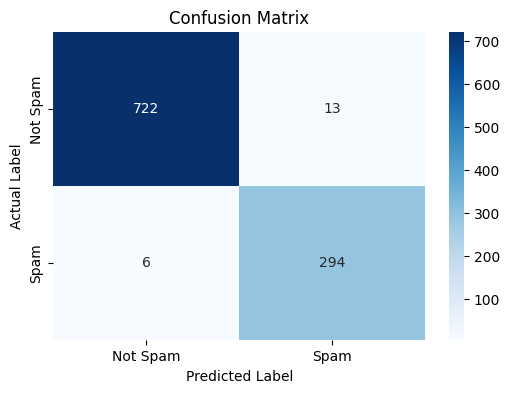

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Spam', 'Spam'],
    yticklabels=['Not Spam', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

**10. Test with Unseen Email Examples**

---



In [ ]:
def predict_email(email):
    cleaned_email = clean_text(email)
    email_vector = tfidf.transform([cleaned_email])
    prediction = model.predict(email_vector)[0]

    if prediction == 1:
        return "Spam Email"
    else:
        return "Not Spam (Legitimate Email)"

In [ ]:
# Test the model

email1 = "Congratulations! You have won a free prize. Click here to claim your reward."
email2 = "Hello, please find attached the meeting schedule for tomorrow."

print("Email 1:", predict_email(email1))
print("Email 2:", predict_email(email2))

Email 1: Spam Email
Email 2: Not Spam (Legitimate Email)


**11. Save the Trained Model**

---


In [ ]:
import joblib

# Save the Logistic Regression model
joblib.dump(lr_model, 'spam_model.pkl')

# Save the TF-IDF vectorizer
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

['tfidf_vectorizer.pkl']